In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scrublet as scr
import session_info
import celltypist
from celltypist import models

In [2]:
import session_info
session_info.show()

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=200, facecolor='white', color_map = 'RdPu',)

In [4]:
adata_endo2=sc.read_h5ad(
    '/path/to/h5ad_subcluster/07_tcell_harmony_bbk.h5ad')

# run celltypist

In [5]:
adata=adata_endo2.raw.to_adata()

In [6]:
model = models.Model.load(model = 'Immune_All_Low.pkl')

In [7]:
model.cell_types

array(['Age-associated B cells', 'Alveolar macrophages', 'B cells',
       'CD16+ NK cells', 'CD16- NK cells', 'CD8a/a', 'CD8a/b(entry)',
       'CMP', 'CRTAM+ gamma-delta T cells', 'Classical monocytes',
       'Cycling B cells', 'Cycling DCs', 'Cycling NK cells',
       'Cycling T cells', 'Cycling gamma-delta T cells',
       'Cycling monocytes', 'DC', 'DC precursor', 'DC1', 'DC2', 'DC3',
       'Double-negative thymocytes', 'Double-positive thymocytes', 'ELP',
       'ETP', 'Early MK', 'Early erythroid', 'Early lymphoid/T lymphoid',
       'Endothelial cells', 'Epithelial cells', 'Erythrocytes',
       'Erythrophagocytic macrophages', 'Fibroblasts',
       'Follicular B cells', 'Follicular helper T cells', 'GMP',
       'Germinal center B cells', 'Granulocytes', 'HSC/MPP',
       'Hofbauer cells', 'ILC', 'ILC precursor', 'ILC1', 'ILC2', 'ILC3',
       'Intermediate macrophages', 'Intestinal macrophages',
       'Kidney-resident macrophages', 'Kupffer cells',
       'Large pre-B cell

In [8]:
predictions = celltypist.annotate(adata,
                                  model = 'Immune_All_Low.pkl', 
                                  majority_voting = True)

🔬 Input data has 812231 cells and 14213 genes
🔗 Matching reference genes in the model
🧬 4766 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 30


running Leiden clustering
    finished: found 630 clusters and added
    'over_clustering', the cluster labels (adata.obs, categorical) (2:50:34)


🗳️ Majority voting the predictions
✅ Majority voting done!


In [9]:
adata_predic = predictions.to_adata()

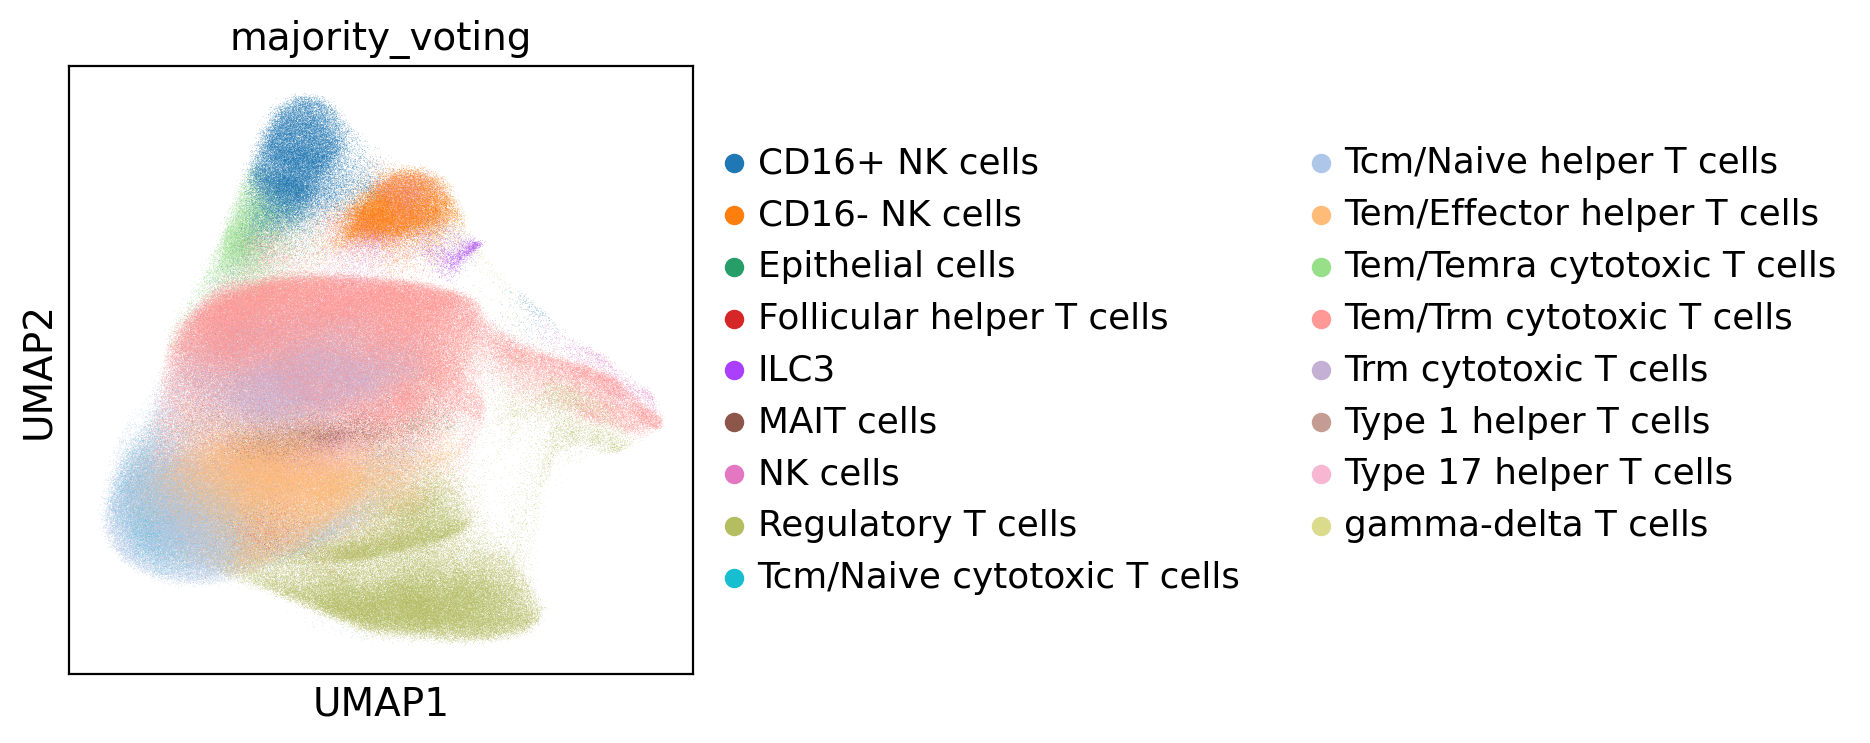

In [10]:
sc.pl.umap(adata_predic, color='majority_voting')

In [11]:
adata_predic.write_h5ad('/path/to/h5ad_subcluster/07_tcell_harmony_bbk_celltypist.h5ad')